# Stern-Gerlach Experiment on IBM Qiskit

The following notebook will simulate a version of the Stern-Gerlach experiment in a quantum circuit using IBM's `qiskit` Python package. We can also use the package `qiskit_ibm_runtime` to run the circuit on actual quantum hardware.

$$\newcommand{\ket}[1]{\left|{#1}\right\rangle}$$
$$\newcommand{\bra}[1]{\left\langle{#1}\right|}$$

## Simulation

In [1]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import random_statevector
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

### Quick Test with $\ket{+}$

To start, we'll create a simple circuit which does the following steps:

1. Initialize a qubit to the state $\ket{0}$, and a classical bit for storing measured outcomes.
2. Apply a Hadamard operation to the qubit which places it in the state $\ket{+}=\frac1{\sqrt{2}}(\ket{0}+\ket{1})$.
3. Measure the qubit and record the outcome.

In [2]:
## Create a quantum circuit with 1 qubit and 1 classical bit
## Qubits default to the state |0>
qc1 = QuantumCircuit(1,1) 

## Apply the Hadamard gate; this transforms the state |0> into the state |+>
qc1.h(0);
## measure the qubit and record in the classical bit
qc1.measure(0,0)

## Draw a diagram of the circuit
qc1.draw(style='clifford')

┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0

Now we'll run this circuit `nShots` times and see the results of our measurement.

Resulting Counts : {'1': 518, '0': 482}


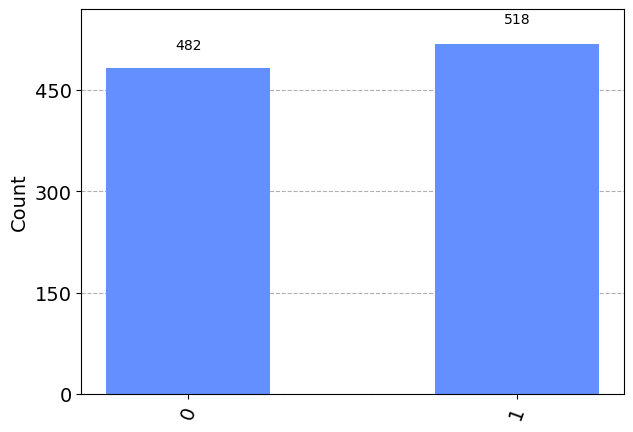

In [3]:
nShots = 1000;

simulator = AerSimulator();
job = simulator.run(qc1, shots=nShots);
results = job.result();
counts = results.get_counts();

print(f"Resulting Counts : {counts}");
plot_histogram(counts)

Here we can see that the results are split pretty evenly between measuring $\ket{0}$ and $\ket{1}$. Since the Hadamard gate places the qubit in the state $\ket{+}$, the result of $\sigma_z$ on the state is split 50/50 between the two eigenstates of $\sigma_z$.

### Stern-Gerlach

For the Stern-Gerlach experiment, we need to initialize random states for the qubit initially. Since IBM doesn't allow you to change the initial state between shots, we'll instead have to make `nShots` separate circuits, each with different initial states. Then, we simply measure the z-component of the spin.

In [4]:
nShots = 1000;

circuits = [];
for j in range(nShots):
    qc = QuantumCircuit(1,1);
    qc.initialize(random_statevector(2).data, 0);
    qc.measure(0,0);
    circuits.append(qc);

In [5]:
## can change index in circuits to check that each one 
## has a different random state
circuits[0].draw(style='clifford')

┌──────────────────────────────────────────────────┐┌─┐
  q: ┤ Initialize(-0.80195-0.37752j,-0.046535+0.46065j) ├┤M├
     └──────────────────────────────────────────────────┘└╥┘
c: 1/═════════════════════════════════════════════════════╩═
                                                          0

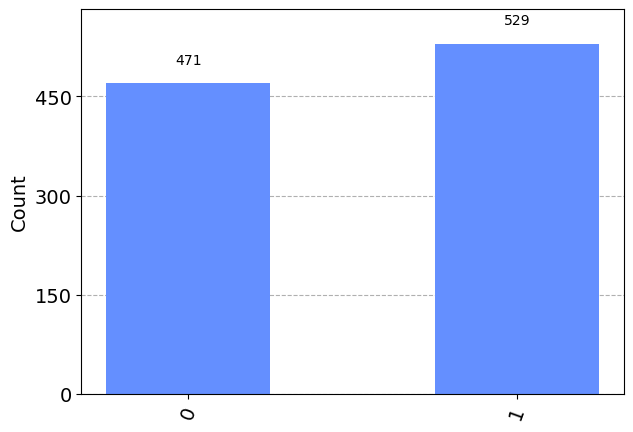

In [6]:
job = simulator.run(circuits, shots=1);
results = job.result();
counts = results.get_counts();

hist_counts = {'0': 0 , '1': 0};
for j in range(nShots):
    if '0' in counts[j].keys():
        hist_counts['0']+=1;
    elif '1' in counts[j].keys():
        hist_counts['1']+=1;

plot_histogram(hist_counts)

Unsurprisingly, the outcomes of this are very similar to the first experiment. About half of the states measure $\ket{0}$, and the other half $\ket{1}$. It's worth noting the reason for this though: in the first experiment, we repeatedly tested the same state which is a perfect 50/50 superposition, but the second experiment, we tested many different states which were randomly distributed, and this randomness averages out to a 50/50 result. The first experiment is like flipping a perfectly fair coin many times, while the second experiment involves flipping many different, randomly weighted coins. 

### Z-X-Z Stern-Gerlach

Finally, we'll perform the alternate Stern-Gerlach setup described in the Spin-1/2 notebook. Suppose we ran our previous circuit, putting random spin states through a measurement of their $\hat{z}$-component. We'll only keep the spins which measure "up", meaning that every spin is in the state $\ket{0}$ before continuing. Next, we'll measure each spin along the $\hat{x}$-axis, splitting them into $\ket{+}$ and $\ket{-}$, then measure along $\hat{z}$ again. 

**Notes:** Since we're pretending everything has already gone through the first $\hat{z}$ measurement, we'll initialize this circuit in the state $\ket{0}$ and only put the $\hat{x}$ and second $\hat{z}$ measures in this circuit. Since `qiskit` only measures along the $\hat{z}$-axis, measuring along $\hat{x}$ looks like a rotation, a measurement, then a rotation back.

In [7]:
def measure_sx(qc,qbit,cbit):
    ## to measure X, rotate Z into X with a π/2 rotation about -Y
    qc.ry(-np.pi/2,qbit)
    ## do the measurement
    qc.measure(qbit,cbit)
    ## rotate back to normal
    qc.ry(np.pi/2,qbit)
    return qc

## initialize circuit in |0> with 2 classical bits for measuring
qc2 = QuantumCircuit(1,2);
## measure X 
qc2 = measure_sx(qc2,0,0);
## measure Z
qc2.measure(0,1);

qc2.draw(style='clifford')

┌──────────┐┌─┐┌─────────┐┌─┐
  q: ┤ Ry(-π/2) ├┤M├┤ Ry(π/2) ├┤M├
     └──────────┘└╥┘└─────────┘└╥┘
c: 2/═════════════╩═════════════╩═
                  0             1

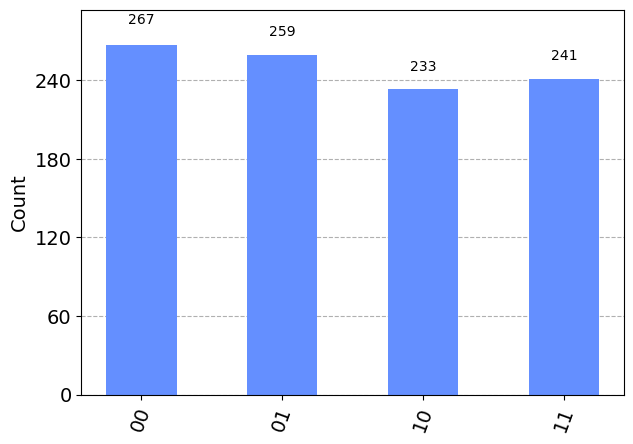

In [8]:
nShots = 1000;

job = simulator.run(qc2, shots=nShots);
results = job.result();
counts = results.get_counts();

plot_histogram(counts)

|`qiskit` label | Measured States |
|---------------|-----------------|
|     `00`      | $\ket{+}\ket{0}$|
|     `01`      | $\ket{-}\ket{0}$|
|     `10`      | $\ket{+}\ket{1}$| 
|     `11`      | $\ket{-}\ket{1}$|

`qiskit` reports measurement results right-to-left, so the key above explains what each number labeled means in terms of states. With that in mind these results show us two big takeaways:
1. The $\sigma_x$ measurement is split about 50/50, which we expected. Since the initial incoming states were all $\ket{0}$, measuring the $\hat{x}$-component is evenly split between $\ket{+}$ and $\ket{-}$.
2. For all the states which measured $\ket{+}$ (and likewise for $\ket{-}$), the final $\sigma_z$ measurement is also split about 50/50. Even though the inital state was $\ket{0}$ for every test, the $\sigma_x$ measurement places those states in a superposition of $\ket{0}$ and $\ket{1}$, meaning that measuring $\sigma_z$ again allows for about 50% of the states to measure $\ket{1}$. Huh, weird.

***
## Real Quantum Hardware

In the following section we can do the same circuits as before, but run them on actual quantum processors at IBM. Doing this requires an IBMQ account, which you can [sign up for free here](https://quantum.ibm.com). From there, you'll need to find your IBMQ API token in your account settings and copy it into the cell below where indicated.

You can view progress on a job submitted to IBMQ by going to the website linked above and looking at your account dashboard; you should see a list of all jobs you've submitted, the backend they're run on, the wait time for a job, and some other info.

In [9]:
from qiskit_ibm_runtime import QiskitRuntimeService, Session, Sampler
## Add your API token below 
QiskitRuntimeService.save_account(channel="ibm_quantum", overwrite=True, token="YOUR_IBM_API_TOKEN_HERE")
service = QiskitRuntimeService()

RequestsApiError: '401 Client Error: Unauthorized for url: https://auth.quantum-computing.ibm.com/api/users/loginWithToken. Login failed., Error code: 3446.'

In [ ]:
## First, find the least busy backend; to see all available backends: print(service.backends())
## We want a backend which is NOT a simulator and is operational (obviously)
backend = service.least_busy(simulator=False, operational=True);
print(f"Backend: {backend.name}")

In [18]:
nShots = 1000;

with Session(service=service, backend=backend.name) as session:
    sampler = Sampler(session=session)

    job = sampler.run(qc2, shots=nShots);
    results = job.result();
    print(f"Counts: {results.quasi_dists}")

Counts: [{0: 0.37784885533676, 1: 0.175262443794076, 2: 0.275254752078055, 3: 0.171633948791109}]


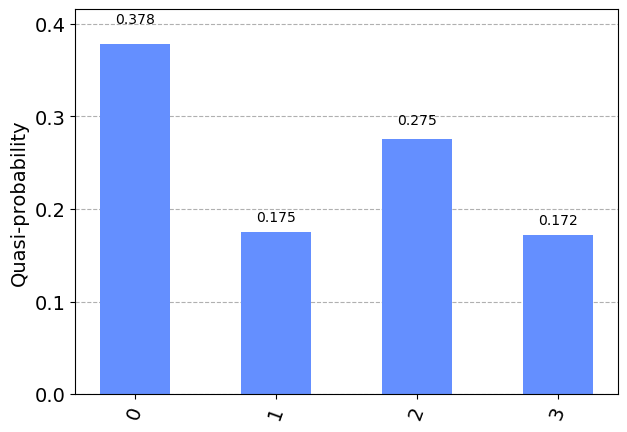

In [19]:
counts = results.quasi_dists
plot_histogram(counts)

# References

 - [Stern-Gerlach IBMQ Blog Post](https://theoreticallyphysics.wordpress.com/2021/09/30/ibm-quantum-qiskit-in-qm-part-ii-stern-gerlach-experiment/)
 - [Qiskit Documentation](https://docs.quantum.ibm.com)